In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
empirical_tail = pd.read_csv(
    "outputs/tables/tail_map_empirical.csv",
    index_col=0
)

copula_tail = pd.read_csv(
    "outputs/tables/tail_map_copula.csv",
    index_col=0
)

stress_change = pd.read_csv(
    "outputs/tables/copula_stress_change.csv",
    index_col=0
)

dfr = pd.read_csv(
    "outputs/tables/diversification_fragility_ratio_final.csv",
    index_col=0
)

copula_models = pd.read_csv(
    "outputs/tables/copula_model_map.csv",
    index_col=0
)

In [3]:
copula_tail.head()

,Short_Normal,Short_Stress,Medium_Normal,Medium_Stress,Long_Normal,Long_Stress
Pair,,,,,,
SPY-TLT,0.017283,0.054336,0.006686,0.060857,0.021429,0.000000
SPY-GLD,0.008786,0.104546,0.022307,0.263295,0.000000,0.168540
SPY-BTC-USD,0.005204,0.119819,0.001685,0.220620,0.075180,0.428123
TLT-GLD,0.065934,0.204184,0.103194,0.176393,0.101947,0.000000
TLT-BTC-USD,0.000000,0.020370,0.000000,0.000000,0.000000,0.000000


In [4]:
portfolio_risk = pd.read_csv(
    "outputs/tables/portfolio_risk_comparison.csv"
)

gaussian_vs_t = pd.read_csv(
    "outputs/tables/gaussian_vs_t_risk_difference.csv",
    index_col=0
)

stress_risk = pd.read_csv(
    "outputs/tables/stress_risk_amplification.csv",
    index_col=0
)

In [5]:
oos_results = pd.read_csv(
    "outputs/tables/out_of_sample_results.csv"
)

oos_es = pd.read_csv(
    "outputs/tables/oos_expected_shortfall_comparison.csv",
    index_col=0
)

In [6]:
backtest_all = pd.read_csv(
    "outputs/tables/backtest_all.csv"
)

stress_backtest = pd.read_csv(
    "outputs/tables/stress_backtest_summary.csv"
)

normal_backtest = pd.read_csv(
    "outputs/tables/normal_backtest_summary.csv"
)

pass_summary = pd.read_csv(
    "outputs/tables/backtest_pass_summary.csv"
)

In [7]:
print("Tail map:", copula_tail.shape)
print("Portfolio risk:", portfolio_risk.shape)
print("OOS results:", oos_results.shape)
print("Backtests:", backtest_all.shape)

Tail map: (6, 6)
Portfolio risk: (18, 5)
OOS results: (12, 17)
Backtests: (24, 19)


In [8]:
column_order = [
    "Short_Normal",
    "Short_Stress",
    "Medium_Normal",
    "Medium_Stress",
    "Long_Normal",
    "Long_Stress"
]

copula_tail = copula_tail[column_order]
empirical_tail = empirical_tail[column_order]

In [9]:
import os

os.makedirs(
    "outputs/figures",
    exist_ok=True
)

os.makedirs(
    "outputs/tables",
    exist_ok=True
)

print("Output folders are ready.")

Output folders are ready.


In [10]:
plt.savefig(
    "outputs/figures/final_tail_risk_map.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

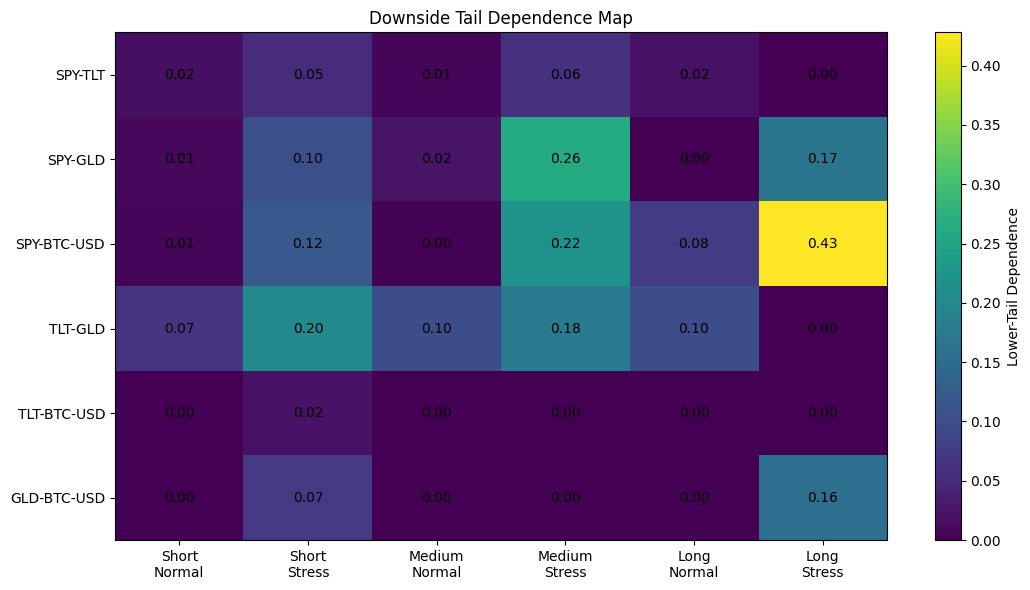

In [11]:
fig, ax = plt.subplots(
    figsize=(11, 6)
)

im = ax.imshow(
    copula_tail.values,
    aspect="auto"
)

ax.set_xticks(
    range(len(copula_tail.columns))
)

ax.set_xticklabels(
    [
        "Short\nNormal",
        "Short\nStress",
        "Medium\nNormal",
        "Medium\nStress",
        "Long\nNormal",
        "Long\nStress"
    ]
)

ax.set_yticks(
    range(len(copula_tail.index))
)

ax.set_yticklabels(
    copula_tail.index
)

for i in range(
    len(copula_tail.index)
):
    for j in range(
        len(copula_tail.columns)
    ):

        value = copula_tail.iloc[
            i, j
        ]

        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center"
        )

plt.colorbar(
    im,
    ax=ax,
    label="Lower-Tail Dependence"
)

ax.set_title(
    "Downside Tail Dependence Map"
)

plt.tight_layout()

plt.savefig(
    "outputs/figures/final_tail_risk_map_values.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
tail_long = (
    copula_tail
    .reset_index()
    .melt(
        id_vars="Pair",
        var_name="Horizon_Regime",
        value_name="Lambda_L"
    )
)

tail_long = tail_long.sort_values(
    "Lambda_L",
    ascending=False
)

tail_long.head(10)

,Pair,Horizon_Regime,Lambda_L
32,SPY-BTC-USD,Long_Stress,0.428123
19,SPY-GLD,Medium_Stress,0.263295
20,SPY-BTC-USD,Medium_Stress,0.220620
9,TLT-GLD,Short_Stress,0.204184
21,TLT-GLD,Medium_Stress,0.176393
31,SPY-GLD,Long_Stress,0.168540
35,GLD-BTC-USD,Long_Stress,0.156779
8,SPY-BTC-USD,Short_Stress,0.119819
7,SPY-GLD,Short_Stress,0.104546
15,TLT-GLD,Medium_Normal,0.103194


In [13]:
stress_long = (
    stress_change
    .reset_index()
    .melt(
        id_vars="Pair",
        var_name="Horizon",
        value_name="Stress_Increase"
    )
)

stress_long = stress_long.sort_values(
    "Stress_Increase",
    ascending=False
)

stress_long.head(10)

,Pair,Horizon,Stress_Increase
14,SPY-BTC-USD,Long,0.352943
7,SPY-GLD,Medium,0.240988
8,SPY-BTC-USD,Medium,0.218935
13,SPY-GLD,Long,0.168540
17,GLD-BTC-USD,Long,0.156779
3,TLT-GLD,Short,0.138250
2,SPY-BTC-USD,Short,0.114615
1,SPY-GLD,Short,0.095760
9,TLT-GLD,Medium,0.073199
5,GLD-BTC-USD,Short,0.070790


In [14]:
tail_long[
    ["Horizon", "Regime"]
] = (
    tail_long[
        "Horizon_Regime"
    ]
    .str.split(
        "_",
        expand=True
    )
)

average_tail = (
    tail_long
    .groupby(
        [
            "Horizon",
            "Regime"
        ]
    )[
        "Lambda_L"
    ]
    .mean()
    .unstack()
)

average_tail

Regime,Normal,Stress
Horizon,,
Long,0.033093,0.125574
Medium,0.022312,0.120194
Short,0.016201,0.095674


In [15]:
average_tail = average_tail.reindex(
    [
        "Short",
        "Medium",
        "Long"
    ]
)

average_tail

Regime,Normal,Stress
Horizon,,
Short,0.016201,0.095674
Medium,0.022312,0.120194
Long,0.033093,0.125574


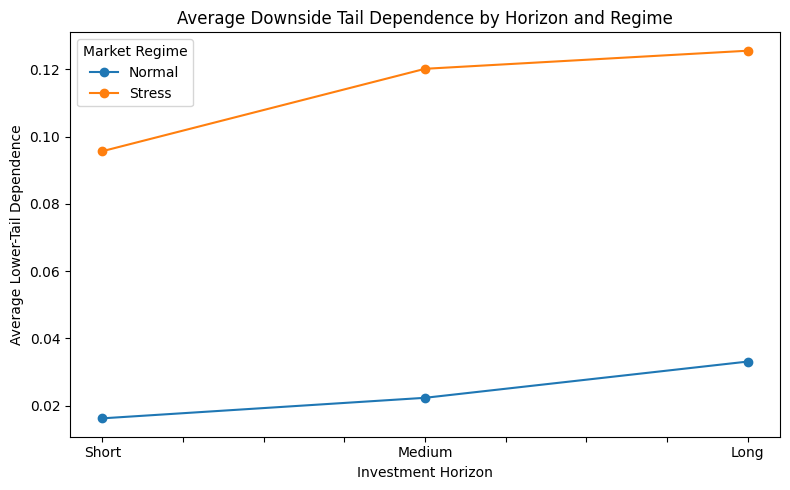

In [16]:
average_tail.plot(
    figsize=(8, 5),
    marker="o"
)

plt.title(
    "Average Downside Tail Dependence by Horizon and Regime"
)

plt.xlabel(
    "Investment Horizon"
)

plt.ylabel(
    "Average Lower-Tail Dependence"
)

plt.legend(
    title="Market Regime"
)

plt.tight_layout()

plt.savefig(
    "outputs/figures/final_average_tail_dependence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
dfr.round(3)

,Short,Medium,Long
Pair,,,
SPY-TLT,3.144,NaN,0.000
SPY-GLD,NaN,11.802,NaN
SPY-BTC-USD,NaN,NaN,5.695
TLT-GLD,3.097,1.709,0.000
TLT-BTC-USD,NaN,NaN,NaN
GLD-BTC-USD,NaN,NaN,NaN


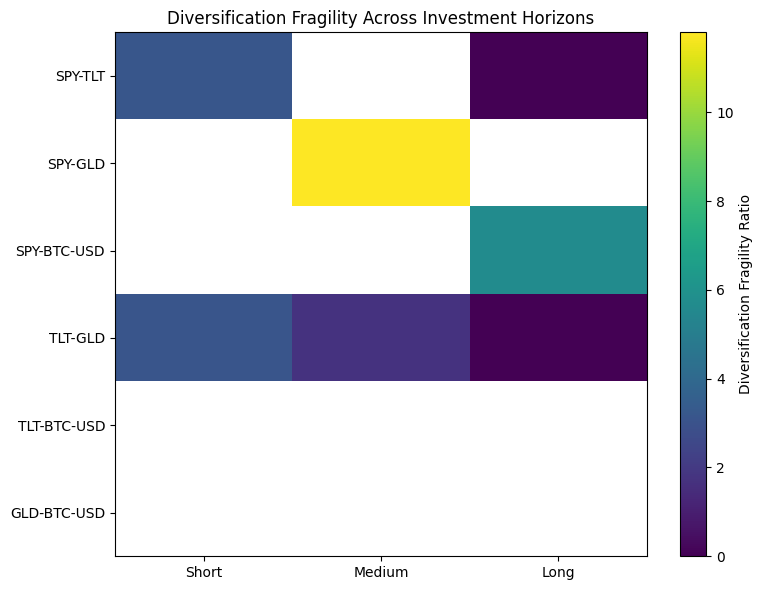

In [18]:
fig, ax = plt.subplots(
    figsize=(8, 6)
)

masked_dfr = np.ma.masked_invalid(
    dfr.values
)

im = ax.imshow(
    masked_dfr,
    aspect="auto"
)

ax.set_xticks(
    range(len(dfr.columns))
)

ax.set_xticklabels(
    dfr.columns
)

ax.set_yticks(
    range(len(dfr.index))
)

ax.set_yticklabels(
    dfr.index
)

plt.colorbar(
    im,
    ax=ax,
    label="Diversification Fragility Ratio"
)

ax.set_title(
    "Diversification Fragility Across Investment Horizons"
)

plt.tight_layout()

plt.savefig(
    "outputs/figures/final_dfr_map.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
copula_models

,Short_Normal,Short_Stress,Medium_Normal,Medium_Stress,Long_Normal,Long_Stress
Pair,,,,,,
GLD-BTC-USD,Gaussian,Student-t,Gumbel,Gumbel,Gumbel,Student-t
SPY-BTC-USD,Student-t,Student-t,Clayton,Student-t,Student-t,Clayton
SPY-GLD,Student-t,Student-t,Student-t,Student-t,Gaussian,Student-t
SPY-TLT,Student-t,Student-t,Student-t,Student-t,Student-t,Gaussian
TLT-BTC-USD,Gaussian,Student-t,Gaussian,Gumbel,Gaussian,Gaussian
TLT-GLD,Student-t,Student-t,Student-t,Student-t,Student-t,Gaussian


In [20]:
model_counts = (
    copula_models
    .stack()
    .value_counts()
)

model_counts

Student-t    22
Gaussian      8
Gumbel        4
Clayton       2
Name: count, dtype: int64

In [21]:
model_transitions = []

for pair in copula_models.index:

    for horizon in [
        "Short",
        "Medium",
        "Long"
    ]:

        normal_model = copula_models.loc[
            pair,
            f"{horizon}_Normal"
        ]

        stress_model = copula_models.loc[
            pair,
            f"{horizon}_Stress"
        ]

        model_transitions.append({
            "Pair": pair,
            "Horizon": horizon,
            "Normal_Model": normal_model,
            "Stress_Model": stress_model,
            "Changed": (
                normal_model
                !=
                stress_model
            )
        })

model_transitions = pd.DataFrame(
    model_transitions
)

model_transitions

,Pair,Horizon,Normal_Model,Stress_Model,Changed
0,GLD-BTC-USD,Short,Gaussian,Student-t,True
1,GLD-BTC-USD,Medium,Gumbel,Gumbel,False
2,GLD-BTC-USD,Long,Gumbel,Student-t,True
3,SPY-BTC-USD,Short,Student-t,Student-t,False
4,SPY-BTC-USD,Medium,Clayton,Student-t,True
5,SPY-BTC-USD,Long,Student-t,Clayton,True
6,SPY-GLD,Short,Student-t,Student-t,False
7,SPY-GLD,Medium,Student-t,Student-t,False
8,SPY-GLD,Long,Gaussian,Student-t,True
9,SPY-TLT,Short,Student-t,Student-t,False


In [22]:
model_transitions[
    "Changed"
].value_counts()

Changed
True     9
False    9
Name: count, dtype: int64

In [23]:
portfolio_risk.head()

,Dataset,Model,VaR_95,VaR_99,ES_97.5
0,Short_Normal,Historical,0.015956,0.028625,0.029446
1,Short_Stress,Historical,0.018235,0.034265,0.039571
2,Medium_Normal,Historical,0.008190,0.012675,0.012858
3,Medium_Stress,Historical,0.009813,0.022494,0.020600
4,Long_Normal,Historical,0.004574,0.005852,0.005737


In [24]:
es_table = portfolio_risk.pivot(
    index="Dataset",
    columns="Model",
    values="ES_97.5"
)

In [25]:
dataset_order = [
    "Short_Normal",
    "Short_Stress",
    "Medium_Normal",
    "Medium_Stress",
    "Long_Normal",
    "Long_Stress"
]

es_table = es_table.reindex(
    dataset_order
)

es_table

Model,Gaussian Copula,Historical,Student-t Copula
Dataset,,,
Short_Normal,0.029602,0.029446,0.029224
Short_Stress,0.033724,0.039571,0.036940
Medium_Normal,0.013393,0.012858,0.013114
Medium_Stress,0.017896,0.020600,0.019360
Long_Normal,0.006251,0.005737,0.006367
Long_Stress,0.007407,0.010506,0.007550


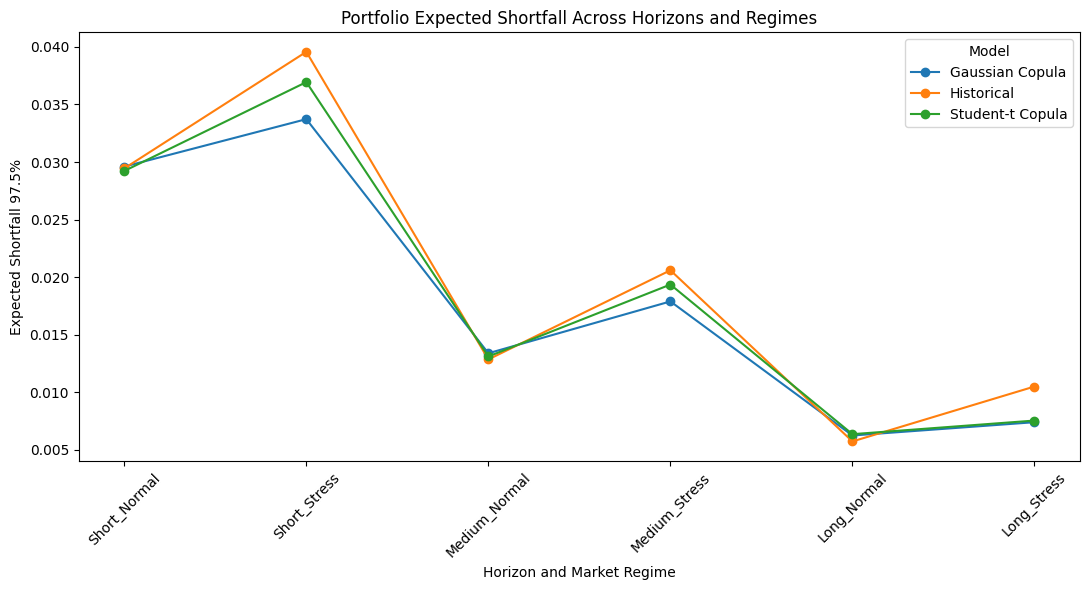

In [26]:
es_table.plot(
    figsize=(11, 6),
    marker="o"
)

plt.title(
    "Portfolio Expected Shortfall Across Horizons and Regimes"
)

plt.xlabel(
    "Horizon and Market Regime"
)

plt.ylabel(
    "Expected Shortfall 97.5%"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.savefig(
    "outputs/figures/final_expected_shortfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
stress_risk.round(3)

,ES_Stress_to_Normal
Short,1.264
Medium,1.476
Long,1.186


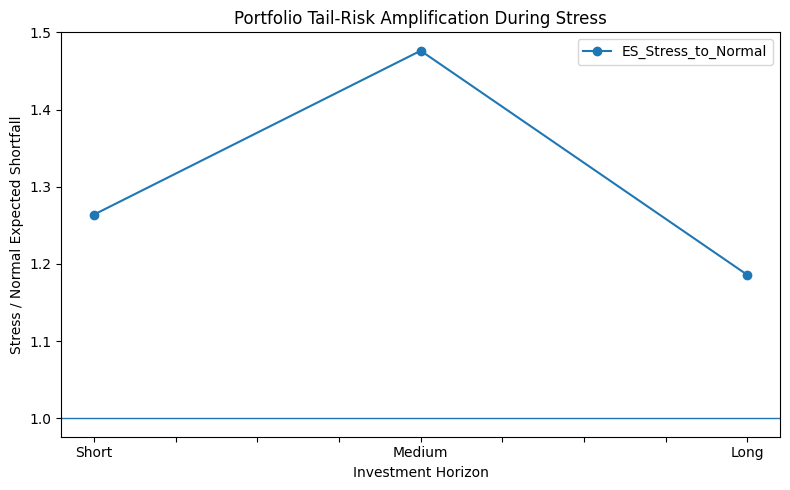

In [28]:
stress_risk.plot(
    figsize=(8, 5),
    marker="o"
)

plt.axhline(
    1,
    linewidth=1
)

plt.title(
    "Portfolio Tail-Risk Amplification During Stress"
)

plt.xlabel(
    "Investment Horizon"
)

plt.ylabel(
    "Stress / Normal Expected Shortfall"
)

plt.tight_layout()

plt.savefig(
    "outputs/figures/final_stress_risk_amplification.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [29]:
gaussian_vs_t

,Gaussian_ES,Student_t_ES,Absolute_Difference,Difference_Percent
Dataset,,,,
Short_Normal,0.029602,0.029224,-0.000378,-1.292511
Short_Stress,0.033724,0.036940,0.003217,8.707768
Medium_Normal,0.013393,0.013114,-0.000278,-2.122871
Medium_Stress,0.017896,0.019360,0.001464,7.563621
Long_Normal,0.006251,0.006367,0.000116,1.816888
Long_Stress,0.007407,0.007550,0.000142,1.885078


In [30]:
risk_difference_sorted = (
    gaussian_vs_t
    .sort_values(
        "Difference_Percent",
        ascending=False
    )
)

risk_difference_sorted

,Gaussian_ES,Student_t_ES,Absolute_Difference,Difference_Percent
Dataset,,,,
Short_Stress,0.033724,0.036940,0.003217,8.707768
Medium_Stress,0.017896,0.019360,0.001464,7.563621
Long_Stress,0.007407,0.007550,0.000142,1.885078
Long_Normal,0.006251,0.006367,0.000116,1.816888
Short_Normal,0.029602,0.029224,-0.000378,-1.292511
Medium_Normal,0.013393,0.013114,-0.000278,-2.122871


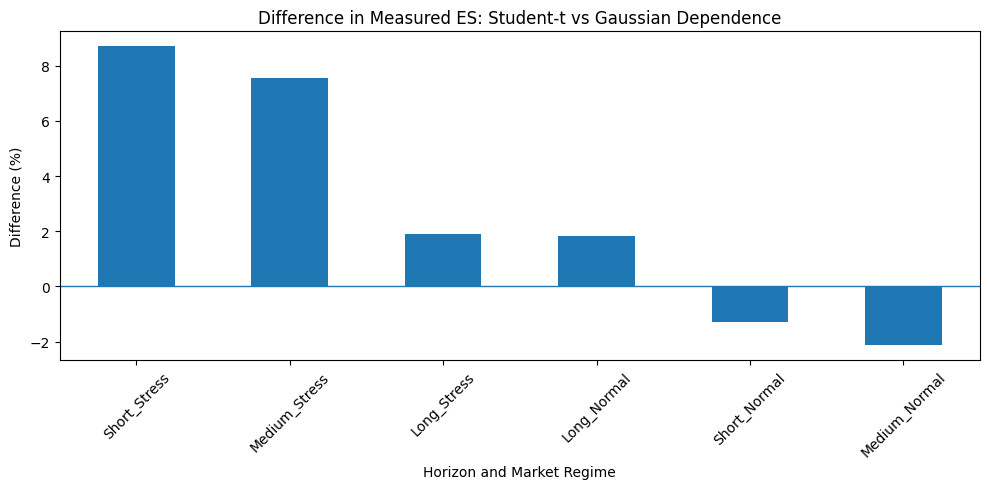

In [31]:
risk_difference_sorted[
    "Difference_Percent"
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.axhline(
    0,
    linewidth=1
)

plt.title(
    "Difference in Measured ES: Student-t vs Gaussian Dependence"
)

plt.xlabel(
    "Horizon and Market Regime"
)

plt.ylabel(
    "Difference (%)"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.savefig(
    "outputs/figures/final_es_model_difference.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
oos_results[
    [
        "Dataset",
        "Model",
        "VaR_95",
        "VaR_99",
        "ES_97.5",
        "Violation_Rate_95",
        "Violation_Rate_99"
    ]
]

,Dataset,Model,VaR_95,VaR_99,ES_97.5,Violation_Rate_95,Violation_Rate_99
0,Short_Normal,Single-Dependence Gaussian,0.016895,0.028486,0.029064,0.021591,0.001136
1,Short_Normal,Regime-Horizon Student-t,0.016514,0.028827,0.029576,0.023864,0.001136
2,Short_Stress,Single-Dependence Gaussian,0.018361,0.031075,0.032613,0.016949,0.000000
3,Short_Stress,Regime-Horizon Student-t,0.018423,0.033896,0.037193,0.016949,0.000000
4,Medium_Normal,Single-Dependence Gaussian,0.008638,0.013508,0.013279,0.020455,0.002273
5,Medium_Normal,Regime-Horizon Student-t,0.008171,0.012676,0.012875,0.025000,0.002273
6,Medium_Stress,Single-Dependence Gaussian,0.009827,0.016954,0.016855,0.033898,0.000000
7,Medium_Stress,Regime-Horizon Student-t,0.010401,0.018924,0.019060,0.033898,0.000000
8,Long_Normal,Single-Dependence Gaussian,0.004492,0.006227,0.006252,0.013636,0.004545
9,Long_Normal,Regime-Horizon Student-t,0.004534,0.006297,0.006408,0.013636,0.003409


In [33]:
violation_95 = oos_results.pivot(
    index="Dataset",
    columns="Model",
    values="Violation_Rate_95"
)

violation_95 = violation_95.reindex(
    dataset_order
)

violation_95

Model,Regime-Horizon Student-t,Single-Dependence Gaussian
Dataset,,
Short_Normal,0.023864,0.021591
Short_Stress,0.016949,0.016949
Medium_Normal,0.025000,0.020455
Medium_Stress,0.033898,0.033898
Long_Normal,0.013636,0.013636
Long_Stress,0.000000,0.000000


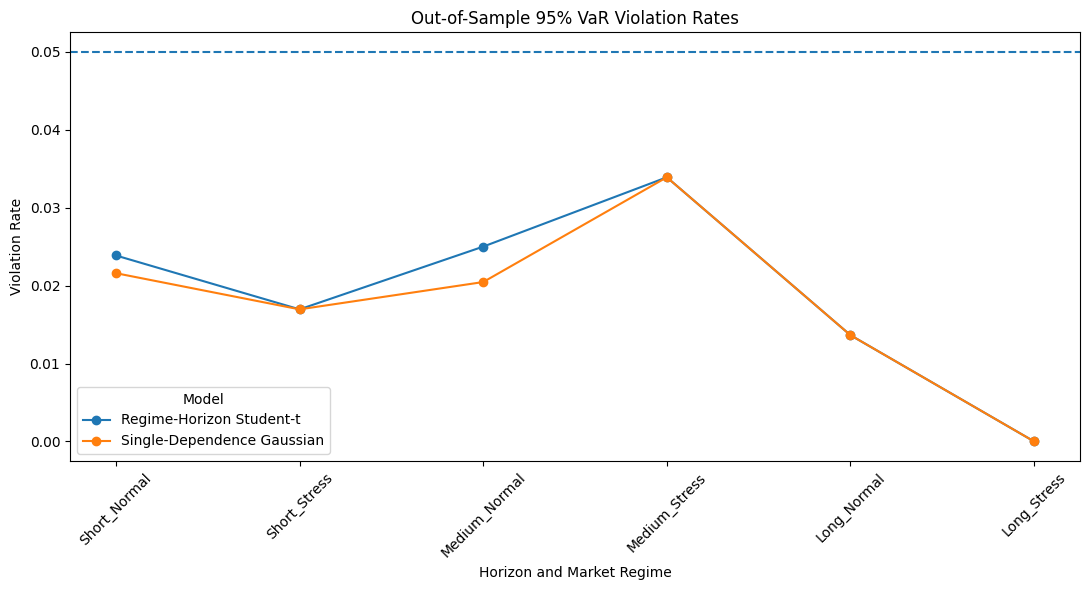

In [34]:
violation_95.plot(
    figsize=(11, 6),
    marker="o"
)

plt.axhline(
    0.05,
    linestyle="--",
    label="Expected 5%"
)

plt.title(
    "Out-of-Sample 95% VaR Violation Rates"
)

plt.xlabel(
    "Horizon and Market Regime"
)

plt.ylabel(
    "Violation Rate"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.savefig(
    "outputs/figures/final_oos_var95.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [35]:
backtest_95 = backtest_all[
    backtest_all["Confidence"]
    ==
    "95%"
].copy()

backtest_95[
    [
        "Dataset",
        "Model",
        "Violation_Rate",
        "Kupiec_p",
        "Christoffersen_p",
        "Conditional_p"
    ]
]

,Dataset,Model,Violation_Rate,Kupiec_p,Christoffersen_p,Conditional_p
0,Short_Normal,Single-Dependence Gaussian,0.021591,1.429211e-05,3.595103e-01,5.356195e-05
1,Short_Normal,Regime-Horizon Student-t,0.023864,7.988429e-05,3.106113e-01,2.498745e-04
2,Short_Stress,Single-Dependence Gaussian,0.016949,1.792951e-01,8.514082e-01,3.988087e-01
3,Short_Stress,Regime-Horizon Student-t,0.016949,1.792951e-01,8.514082e-01,3.988087e-01
4,Medium_Normal,Single-Dependence Gaussian,0.020455,5.592276e-06,9.667767e-11,2.664535e-14
5,Medium_Normal,Regime-Horizon Student-t,0.025000,1.756203e-04,1.349321e-10,9.756640e-13
6,Medium_Stress,Single-Dependence Gaussian,0.033898,5.477411e-01,3.208249e-02,8.393341e-02
7,Medium_Stress,Regime-Horizon Student-t,0.033898,5.477411e-01,3.208249e-02,8.393341e-02
8,Long_Normal,Single-Dependence Gaussian,0.013636,5.435950e-09,0.000000e+00,0.000000e+00
9,Long_Normal,Regime-Horizon Student-t,0.013636,5.435950e-09,0.000000e+00,0.000000e+00


In [36]:
formal_summary = (
    backtest_95
    .groupby("Model")
    .agg(
        Mean_Violation_Rate=(
            "Violation_Rate",
            "mean"
        ),
        Mean_Absolute_Error=(
            "Absolute_Violation_Error",
            "mean"
        ),
        Kupiec_Passes=(
            "Kupiec_Pass",
            "sum"
        ),
        Independence_Passes=(
            "Independence_Pass",
            "sum"
        ),
        Conditional_Passes=(
            "Conditional_Pass",
            "sum"
        )
    )
)

formal_summary

,Mean_Violation_Rate,Mean_Absolute_Error,Kupiec_Passes,Independence_Passes,Conditional_Passes
Model,,,,,
Regime-Horizon Student-t,0.018891,0.031109,2,2,2
Single-Dependence Gaussian,0.017755,0.032245,2,2,2


In [37]:
stress_95 = backtest_95[
    backtest_95["Regime"]
    ==
    "Stress"
]

stress_95[
    [
        "Dataset",
        "Model",
        "Violation_Rate",
        "Kupiec_p",
        "Conditional_p"
    ]
]

,Dataset,Model,Violation_Rate,Kupiec_p,Conditional_p
2,Short_Stress,Single-Dependence Gaussian,0.016949,0.179295,0.398809
3,Short_Stress,Regime-Horizon Student-t,0.016949,0.179295,0.398809
6,Medium_Stress,Single-Dependence Gaussian,0.033898,0.547741,0.083933
7,Medium_Stress,Regime-Horizon Student-t,0.033898,0.547741,0.083933
10,Long_Stress,Single-Dependence Gaussian,0.000000,0.013886,NaN
11,Long_Stress,Regime-Horizon Student-t,0.000000,0.013886,NaN


In [38]:
tail_summary = average_tail.copy()

tail_summary

Regime,Normal,Stress
Horizon,,
Short,0.016201,0.095674
Medium,0.022312,0.120194
Long,0.033093,0.125574


In [39]:
student_t_es = es_table[
    "Student-t Copula"
]

portfolio_es_summary = pd.DataFrame({
    "Normal": [
        student_t_es["Short_Normal"],
        student_t_es["Medium_Normal"],
        student_t_es["Long_Normal"]
    ],

    "Stress": [
        student_t_es["Short_Stress"],
        student_t_es["Medium_Stress"],
        student_t_es["Long_Stress"]
    ]
},
index=[
    "Short",
    "Medium",
    "Long"
])

portfolio_es_summary

,Normal,Stress
Short,0.029224,0.03694
Medium,0.013114,0.01936
Long,0.006367,0.00755


In [40]:
final_summary = pd.DataFrame(
    index=[
        "Short",
        "Medium",
        "Long"
    ]
)

final_summary[
    "Average_Tail_Normal"
] = (
    average_tail["Normal"]
)

final_summary[
    "Average_Tail_Stress"
] = (
    average_tail["Stress"]
)

final_summary[
    "Tail_Stress_Change"
] = (
    final_summary[
        "Average_Tail_Stress"
    ]
    -
    final_summary[
        "Average_Tail_Normal"
    ]
)

final_summary[
    "Portfolio_ES_Normal"
] = (
    portfolio_es_summary[
        "Normal"
    ]
)

final_summary[
    "Portfolio_ES_Stress"
] = (
    portfolio_es_summary[
        "Stress"
    ]
)

final_summary[
    "ES_Stress_Ratio"
] = (
    final_summary[
        "Portfolio_ES_Stress"
    ]
    /
    final_summary[
        "Portfolio_ES_Normal"
    ]
)

final_summary

,Average_Tail_Normal,Average_Tail_Stress,Tail_Stress_Change,Portfolio_ES_Normal,Portfolio_ES_Stress,ES_Stress_Ratio
Short,0.016201,0.095674,0.079473,0.029224,0.03694,1.264041
Medium,0.022312,0.120194,0.097882,0.013114,0.01936,1.476302
Long,0.033093,0.125574,0.092481,0.006367,0.00755,1.185835


In [41]:
final_summary.to_csv(
    "outputs/tables/final_research_summary.csv"
)

In [42]:
strongest_tail = tail_long.iloc[0]

print(
    "Strongest tail dependence:"
)

print(
    strongest_tail
)

Strongest tail dependence:
Pair              SPY-BTC-USD
Horizon_Regime    Long_Stress
Lambda_L             0.428123
Horizon                  Long
Regime                 Stress
Name: 32, dtype: object


In [43]:
largest_stress_increase = (
    stress_long.iloc[0]
)

print(
    "Largest stress increase:"
)

print(
    largest_stress_increase
)

Largest stress increase:
Pair               SPY-BTC-USD
Horizon                   Long
Stress_Increase       0.352943
Name: 14, dtype: object


In [44]:
largest_risk_difference = (
    risk_difference_sorted.iloc[0]
)

print(
    "Largest Gaussian vs Student-t ES difference:"
)

print(
    largest_risk_difference
)

Largest Gaussian vs Student-t ES difference:
Gaussian_ES            0.033724
Student_t_ES           0.036940
Absolute_Difference    0.003217
Difference_Percent     8.707768
Name: Short_Stress, dtype: float64


In [45]:
best_calibration = (
    backtest_95
    .sort_values(
        "Absolute_Violation_Error"
    )
)

best_calibration[
    [
        "Dataset",
        "Model",
        "Violation_Rate",
        "Expected_Rate",
        "Absolute_Violation_Error",
        "Kupiec_p"
    ]
].head(10)

,Dataset,Model,Violation_Rate,Expected_Rate,Absolute_Violation_Error,Kupiec_p
6,Medium_Stress,Single-Dependence Gaussian,0.033898,0.05,0.016102,5.477411e-01
7,Medium_Stress,Regime-Horizon Student-t,0.033898,0.05,0.016102,5.477411e-01
5,Medium_Normal,Regime-Horizon Student-t,0.025000,0.05,0.025000,1.756203e-04
1,Short_Normal,Regime-Horizon Student-t,0.023864,0.05,0.026136,7.988429e-05
0,Short_Normal,Single-Dependence Gaussian,0.021591,0.05,0.028409,1.429211e-05
4,Medium_Normal,Single-Dependence Gaussian,0.020455,0.05,0.029545,5.592276e-06
3,Short_Stress,Regime-Horizon Student-t,0.016949,0.05,0.033051,1.792951e-01
2,Short_Stress,Single-Dependence Gaussian,0.016949,0.05,0.033051,1.792951e-01
8,Long_Normal,Single-Dependence Gaussian,0.013636,0.05,0.036364,5.435950e-09
9,Long_Normal,Regime-Horizon Student-t,0.013636,0.05,0.036364,5.435950e-09


In [46]:
tail_long.to_csv(
    "outputs/tables/final_tail_rankings.csv",
    index=False
)

stress_long.to_csv(
    "outputs/tables/final_stress_tail_changes.csv",
    index=False
)

formal_summary.to_csv(
    "outputs/tables/final_backtest_summary.csv"
)

portfolio_es_summary.to_csv(
    "outputs/tables/final_portfolio_es_summary.csv"
)

model_transitions.to_csv(
    "outputs/tables/final_model_transitions.csv",
    index=False
)

In [47]:
print(
    "Notebook 11 completed successfully."
)

print(
    "\nFINAL RESEARCH SUMMARY"
)

display(
    final_summary.round(4)
)

print(
    "\nSTRONGEST TAIL DEPENDENCE"
)

display(
    tail_long.head(5)
)

print(
    "\nLARGEST STRESS INCREASES"
)

display(
    stress_long.head(5)
)

print(
    "\n95% FORMAL BACKTEST SUMMARY"
)

display(
    formal_summary.round(4)
)

Notebook 11 completed successfully.

FINAL RESEARCH SUMMARY


,Average_Tail_Normal,Average_Tail_Stress,Tail_Stress_Change,Portfolio_ES_Normal,Portfolio_ES_Stress,ES_Stress_Ratio
Short,0.0162,0.0957,0.0795,0.0292,0.0369,1.2640
Medium,0.0223,0.1202,0.0979,0.0131,0.0194,1.4763
Long,0.0331,0.1256,0.0925,0.0064,0.0075,1.1858



STRONGEST TAIL DEPENDENCE


,Pair,Horizon_Regime,Lambda_L,Horizon,Regime
32,SPY-BTC-USD,Long_Stress,0.428123,Long,Stress
19,SPY-GLD,Medium_Stress,0.263295,Medium,Stress
20,SPY-BTC-USD,Medium_Stress,0.220620,Medium,Stress
9,TLT-GLD,Short_Stress,0.204184,Short,Stress
21,TLT-GLD,Medium_Stress,0.176393,Medium,Stress



LARGEST STRESS INCREASES


,Pair,Horizon,Stress_Increase
14,SPY-BTC-USD,Long,0.352943
7,SPY-GLD,Medium,0.240988
8,SPY-BTC-USD,Medium,0.218935
13,SPY-GLD,Long,0.168540
17,GLD-BTC-USD,Long,0.156779



95% FORMAL BACKTEST SUMMARY


,Mean_Violation_Rate,Mean_Absolute_Error,Kupiec_Passes,Independence_Passes,Conditional_Passes
Model,,,,,
Regime-Horizon Student-t,0.0189,0.0311,2,2,2
Single-Dependence Gaussian,0.0178,0.0322,2,2,2
